# Phase 1: Enhancement (charvi, LIVER, patient 1)

| Step | This member's algorithms |
|---|---|
| Windowing | abdomen window, level 40 / width 400 |
| Spatial filter | **anisotropic diffusion** (edge-preserving) vs **Gaussian** blur |
| Contrast | **CLAHE** vs **histogram equalisation** |
| Frequency | 2D DFT spectrum + **homomorphic filter** |
| Validation | PSNR + CNR |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "charvi"
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_charvi"                         # phase1/outputs_charvi
FIGS = "../report/figures/charvi"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    base = ct_path.replace("_ct.npy", "")
    return np.load(ct_path), cv2.imread(base + "_liver.png", 0) > 0, cv2.imread(base + "_tumour.png", 0) > 0

example = max(files, key=lambda f: load(f)[1].sum())     # slice with the biggest liver
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example))

18 slices found
example slice: p1_s65_ct.npy


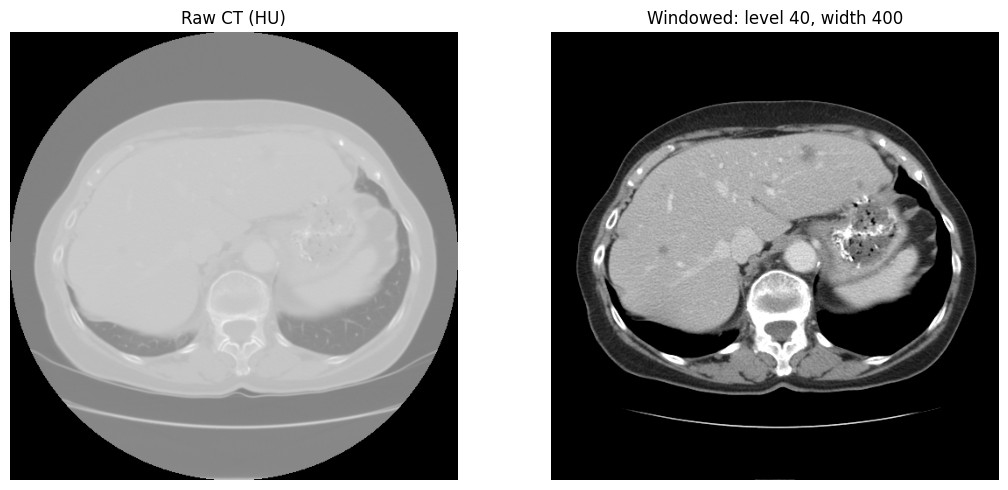

In [2]:
def window(ct, level=40, width=400):
    """Keep the soft-tissue HU range and stretch it to 0-255."""
    lo, hi = level - width / 2, level + width / 2
    return ((np.clip(ct, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

def crop(img):
    return img[100:420, 40:400]

win = window(ct)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title("Raw CT (HU)")
ax[1].imshow(win, cmap="gray"); ax[1].set_title("Windowed: level 40, width 400")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

**Spatial filtering.** *Anisotropic diffusion* repeatedly lets brightness "flow" between neighbouring pixels, but the flow is blocked wherever the difference is large (an edge). *Gaussian* blur averages everything with a bell-shaped weight, so edges get blurred too.

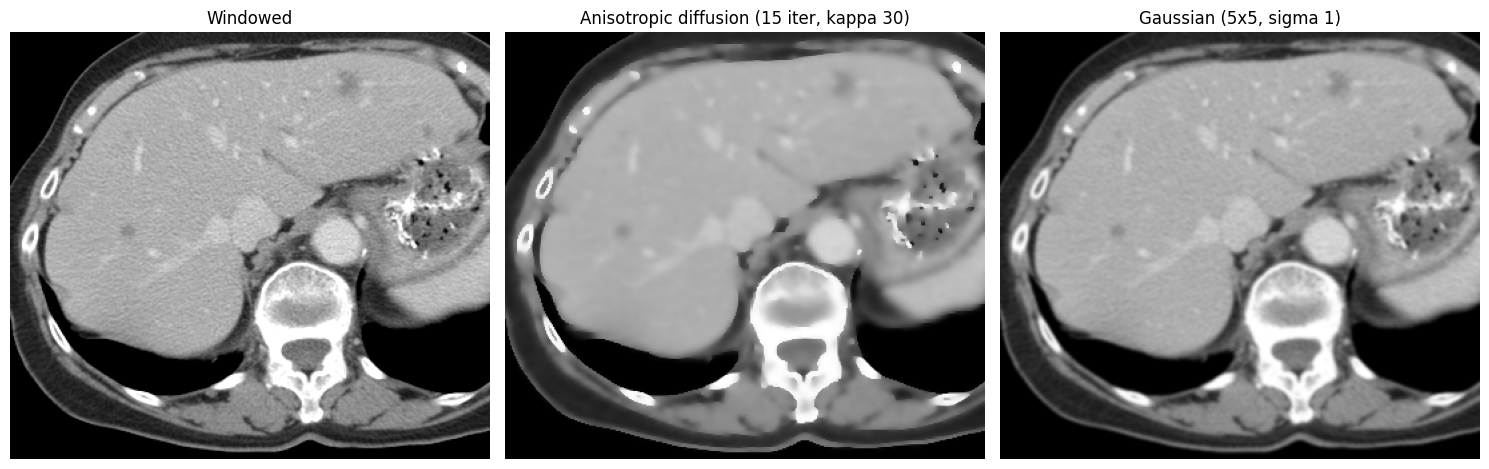

In [3]:
def anisotropic_diffusion(img, iterations=15, kappa=30, gamma=0.15):
    """Perona-Malik diffusion: smooths flat areas, but stops at edges (big brightness jumps)."""
    I = img.astype(np.float64)
    for _ in range(iterations):
        # differences to the 4 neighbours (north, south, east, west)
        diffs = [np.roll(I, -1, 0) - I, np.roll(I, 1, 0) - I, np.roll(I, -1, 1) - I, np.roll(I, 1, 1) - I]
        # conduction: close to 1 for small differences (smooth), close to 0 at edges (keep)
        I = I + gamma * sum(np.exp(-(d / kappa) ** 2) * d for d in diffs)
    return np.clip(I, 0, 255).astype(np.uint8)

aniso = anisotropic_diffusion(win)
gauss = cv2.GaussianBlur(win, (5, 5), 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [win, aniso, gauss], ["Windowed", "Anisotropic diffusion (15 iter, kappa 30)", "Gaussian (5x5, sigma 1)"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

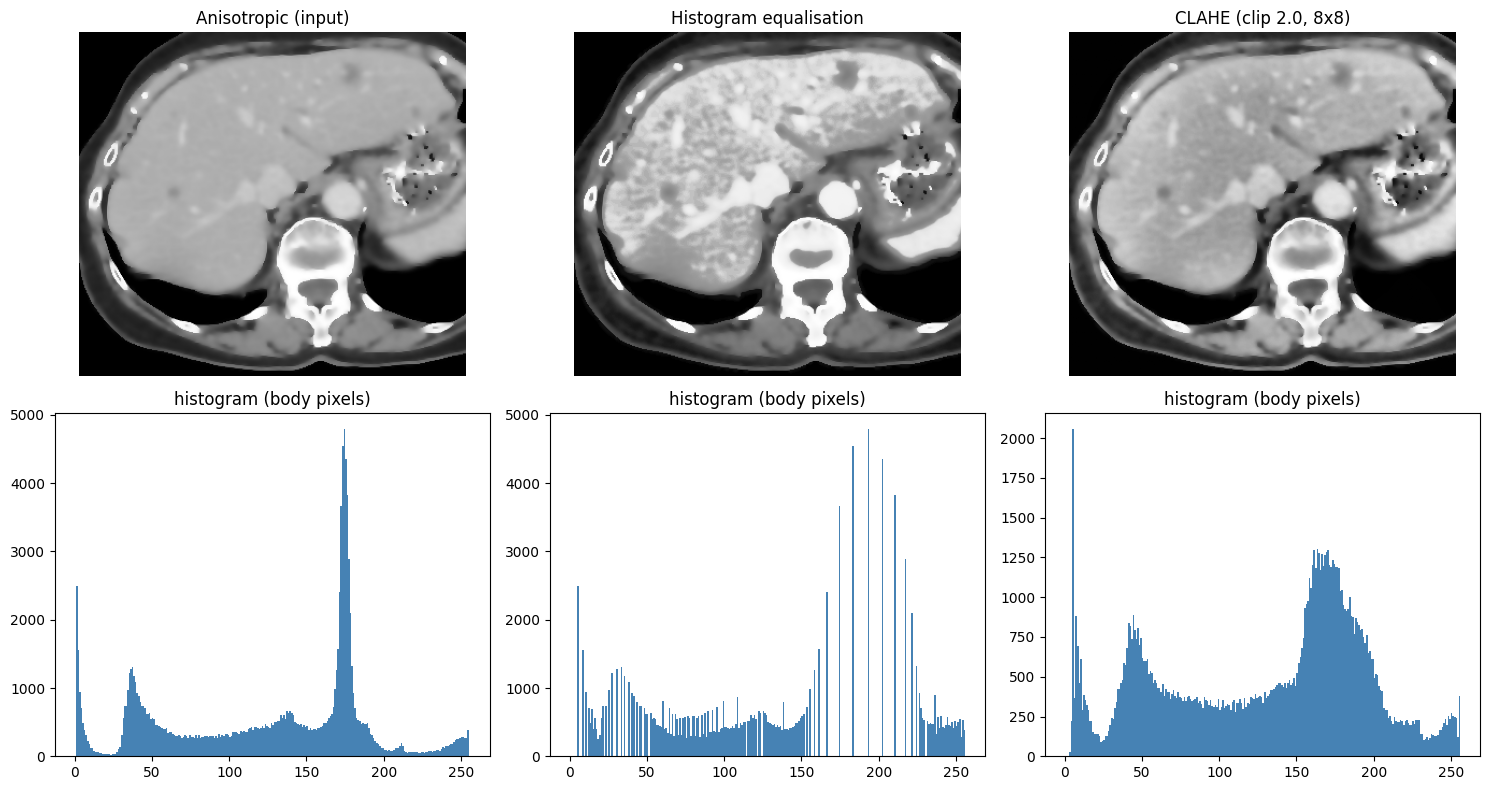

In [4]:
he = cv2.equalizeHist(aniso)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(aniso)
body = aniso > 0
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(aniso, "Anisotropic (input)"), (he, "Histogram equalisation"), (clahe, "CLAHE (clip 2.0, 8x8)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[body].ravel(), bins=256, range=(0, 256), color="steelblue"); ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

**Frequency domain: homomorphic filter.** An image can be seen as *lighting x reflectance*. Taking the log turns the multiplication into addition, so the slowly-changing lighting (low frequencies) and the fine detail (high frequencies) can be treated separately: the filter turns low frequencies **down** (x0.7) and high frequencies **up** (x1.3).

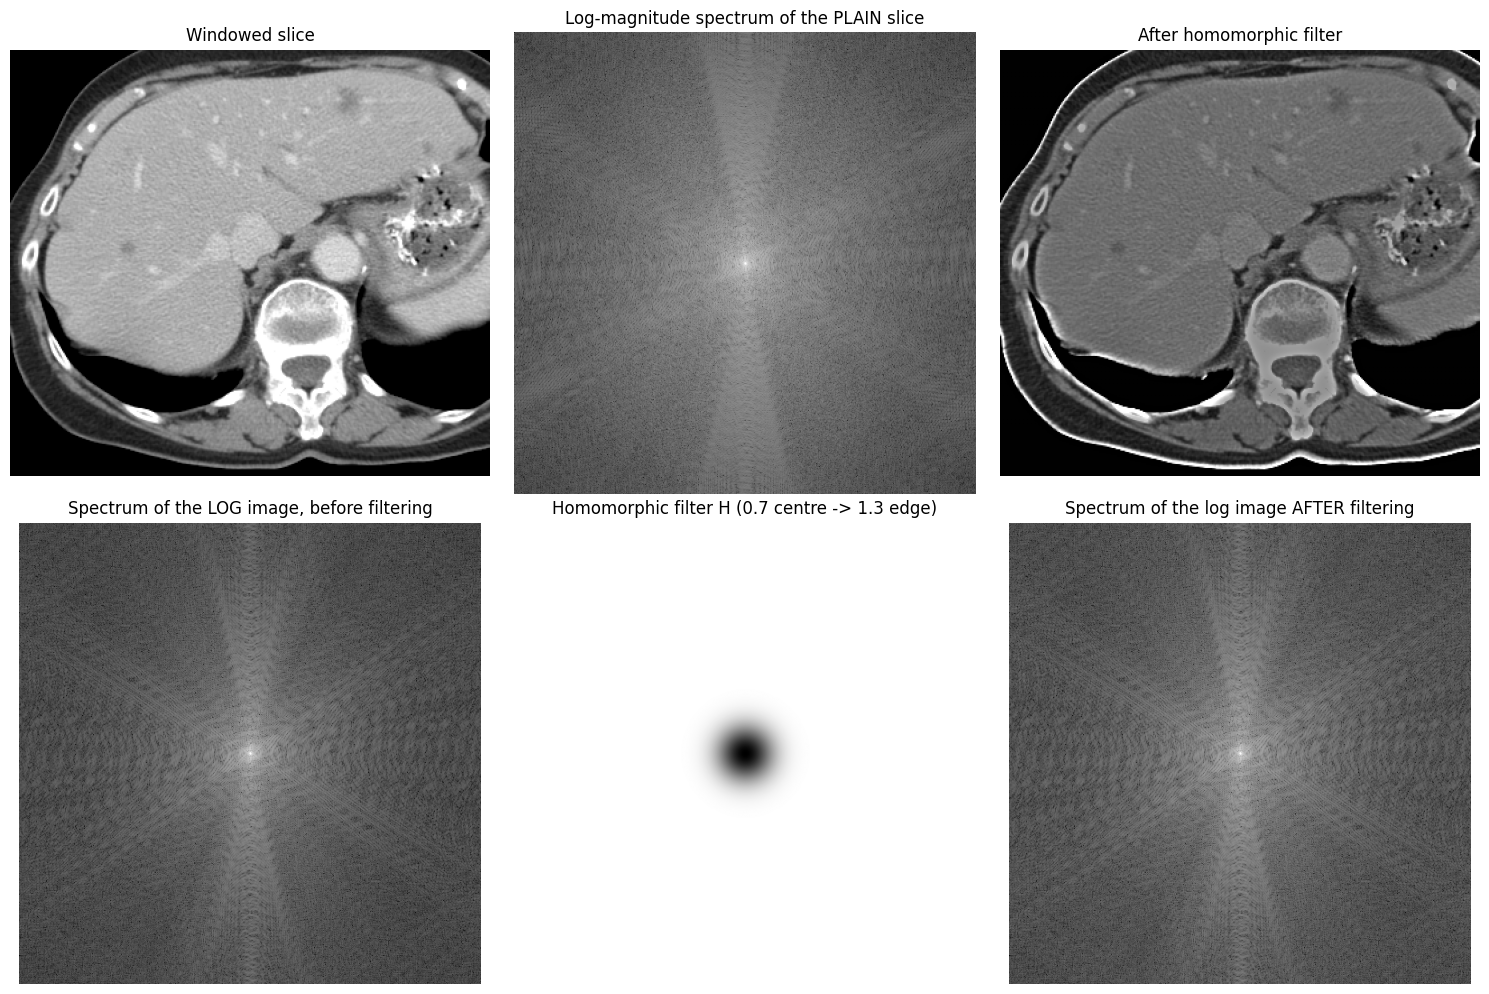

In [5]:
def homomorphic(img, D0=30, gamma_low=0.7, gamma_high=1.3, c=1):
    """Homomorphic filter: image = lighting x reflectance. Taking the log turns x into +,
    then a high-emphasis filter turns DOWN slow lighting changes and turns UP detail."""
    F = np.fft.fftshift(np.fft.fft2(np.log1p(img.astype(np.float64))))
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D2 = u ** 2 + v ** 2
    H = (gamma_high - gamma_low) * (1 - np.exp(-c * D2 / D0 ** 2)) + gamma_low
    out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(F * H))))
    lo, hi = np.percentile(out, [1, 99])                  # robust rescale: ignore the few extreme edge pixels
    out = np.clip((out - lo) / (hi - lo + 1e-9), 0, 1) * 255
    return out.astype(np.uint8), F, H

homo, F, H = homomorphic(win)
F_plain = np.fft.fftshift(np.fft.fft2(win.astype(np.float64)))      # spectrum of the plain slice (no log, no filter)
log_mag = lambda F: np.log(1 + np.abs(F))
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(crop(win), cmap="gray"); ax[0, 0].set_title("Windowed slice")
ax[0, 1].imshow(log_mag(F_plain), cmap="gray"); ax[0, 1].set_title("Log-magnitude spectrum of the PLAIN slice")
ax[0, 2].imshow(crop(homo), cmap="gray"); ax[0, 2].set_title("After homomorphic filter")
ax[1, 0].imshow(log_mag(F), cmap="gray"); ax[1, 0].set_title("Spectrum of the LOG image, before filtering")
ax[1, 1].imshow(H, cmap="gray"); ax[1, 1].set_title("Homomorphic filter H (0.7 centre -> 1.3 edge)")
ax[1, 2].imshow(log_mag(F * H), cmap="gray"); ax[1, 2].set_title("Spectrum of the log image AFTER filtering")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the original (dB). Higher = less changed."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    an = anisotropic_diffusion(win)
    versions = {"windowed": win, "anisotropic": an, "gaussian": cv2.GaussianBlur(win, (5, 5), 1),
                "homomorphic": homomorphic(win)[0], "aniso+HE": cv2.equalizeHist(an),
                "aniso+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(an)}
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),
                     "CNR liver vs surroundings": cnr(im, liver, ring),
                     "CNR tumour vs liver": cnr(im, tumour, liver & ~tumour)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
print(results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2))

              PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                            
windowed       NaN                       1.19                 1.56
anisotropic  31.88                       1.23                 1.77
gaussian     30.73                       1.24                 1.77
homomorphic  17.75                       0.70                 1.14
aniso+HE     24.78                       1.39                 1.75
aniso+CLAHE  26.27                       1.16                 1.92


**Controlled noise test.** PSNR against the windowed slice only says how much a filter *changed* the image, not whether it improved it. Here the windowed slice is treated as the clean reference, Gaussian noise with a known strength (sigma = 40 HU, added to the CT **before** windowing, so every member's window scales it like real CT noise; 40 HU is well above the CT's own noise) is added, and each filter has to remove it. PSNR and SSIM (structural similarity: 1 = same structure) are measured against the clean slice, on tissue pixels only (not on clipped black air or white bone), so higher really means "closer to the truth". (The windowed slice already contains some CT noise, so this measures how well each filter removes *added* noise.)

In [7]:
from skimage.metrics import structural_similarity as ssim

NOISE_SIGMA_HU = 40      # same physical noise for every member, added in HU BEFORE windowing
noise_rng = np.random.default_rng(0)
rows = []
for f in files:
    ct = load(f)[0]
    clean = window(ct)
    noisy = window(ct + noise_rng.normal(0, NOISE_SIGMA_HU, ct.shape))   # each window scales the noise like real CT noise
    # score only tissue that is not clipped in the clean slice: in black air / white bone the noise can only go one way
    # and is clipped away, which would reward filters (e.g. median) just for restoring flat black or white areas
    tissue = (clean > 0) & (clean < 255)
    filtered = {"noisy (no filter)": noisy, "anisotropic": anisotropic_diffusion(noisy), "gaussian": cv2.GaussianBlur(noisy, (5, 5), 1),
                "homomorphic": homomorphic(noisy)[0]}
    for method, im in filtered.items():
        _, ssim_map = ssim(clean, im, data_range=255, full=True)
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR vs clean": psnr(clean[tissue], im[tissue]), "SSIM vs clean": ssim_map[tissue].mean()})
noise_test = pd.DataFrame(rows)
noise_test.to_csv(f"{OUT}/phase1_noise_test.csv", index=False)
print(f"Added Gaussian noise in HU, sigma = {NOISE_SIGMA_HU} HU (before windowing):")
print(noise_test.groupby("method", sort=False)[["PSNR vs clean", "SSIM vs clean"]].mean().round(3))

Added Gaussian noise in HU, sigma = 40 HU (before windowing):
                   PSNR vs clean  SSIM vs clean
method                                         
noisy (no filter)         20.177          0.457
anisotropic               25.450          0.693
gaussian                  26.377          0.759
homomorphic               12.221          0.376


**Final enhancement chosen:** windowing -> anisotropic diffusion -> CLAHE. Anisotropic diffusion keeps the liver edge sharp (good for region growing in Phase 2) and CLAHE raises local contrast without the strong graininess of global HE.

In [8]:
for f in files:
    ct, _, _ = load(f)
    enh = cv2.createCLAHE(2.0, (8, 8)).apply(anisotropic_diffusion(window(ct)))
    cv2.imwrite(f"{OUT}/enhanced/{os.path.basename(f).replace('_ct.npy', '_enh.png')}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 18 enhanced slices to outputs_charvi/enhanced
